## <span style="color:red"> Exercises </span>

<font size = "3">

**Ex. 1** If we invest $P$ dollars in an account with interest rate $r$, compounded $n$ times yearly, then after $t$ years the account is worth:

$$V=P\left(1+{\frac {r}{n}}\right)^{nt}$$

Write a custom function that takes in the values of $P$, $r$, $n$, and $t$ and returns the final value $V$.

**Note**: For this formula, if the interest rate is 3%, then we would pass $r = 0.03$ into the function, not the number 3.

In [5]:
# SOLUTION

def calculate_amount(P, r, n, t):
    frac = r/n 
    base = 1 + frac
    exponent = n*t
    V = P * base ** exponent 
    return V

# Or you can be more concise...
def calculate_amount_v2(P, r, n, t):
    return P * (1 + r/n) ** (n*t)

<font size = "3">

Using your function, evaluate and print the final value if you invest $100$ dollars in an account with 1% interest rate, compounded 20 times a year, for 10 years 

In [6]:
# SOLUTION

# passing arguments with keywords...
amount = calculate_amount(P = 100, r = 0.01, n = 20, t = 10)
print(amount)

# ...and without
amount = calculate_amount_v2(100, 0.01, 20, 10)
print(amount)



110.51432983541218
110.51432983541218


<font size = "3">

Using your function, evaluate and print the final value if you invest $1000$ dollars in an account with 5% interest rate, compounded 35 times a year, for 15 years

In [7]:
# SOLUTION

print(calculate_amount(1000, .05, 35, 15))


2115.867291553817


<font size = "3">

**Ex 2.** Try redoing the birthday paradox lab with a function inside of a loop instead of a loop inside of a loop (it's okay for the function to contain a loop). Does it make it easier to read and understand the code? Can you write a single function that takes room size as an argument and returns an estimated probability of two people having the same birthday?

In [8]:
# Setup code
import random
# The 50 people in our room (each entry is [name, month, day, year])
birthdays = [
    ["Abed", "March", 23, 2007],
    ["Britta", "July", 14, 1998],
    ["Jeff", "December", 8, 1990],
    ["Shirley", "January", 19, 1990],
    ["Annie", "September", 27, 2007],
    ["Troy", "June", 5, 2007],
    ["Pierce", "December", 30, 1962],
    ["Chang", "April", 17, 1987],
    ["Craig", "August", 11, 1985],
    ["Magnitude", "February", 22, 1983],
    ["Garrett", "October", 3, 2001],
    ["Vicki", "May", 29, 2003],
    ["Todd", "March", 16, 1997],
    ["Starburns", "July", 7, 1982],
    ["Neil", "January", 25, 1998],
    ["Leonard", "November", 13, 1993],
    ["Willy", "September", 4, 1981],
    ["Pavel", "June", 21, 1980],
    ["Quendra", "December", 9, 1982],
    ["Rich", "April", 28, 1986],
    ["Duncan", "August", 15, 1987],
    ["Hickey", "February", 6, 1996],
    ["Buzz", "October", 24, 1999],
    ["Rachel", "May", 18, 1980],
    ["Ian", "March", 12, 1997],
    ["Elroy", "July", 30, 1986],
    ["Frankie", "November", 2, 2002],
    ["Natalie", "September", 20, 2000],
    ["Owen", "June", 11, 2002],
    ["Paula", "December", 26, 1997],
    ["Quinn", "April", 1, 1993],
    ["Roger", "August", 17, 1987],
    ["Sara", "February", 8, 1994],
    ["Tim", "October", 22, 1998],
    ["Uma", "May", 14, 1988],
    ["Victor", "January", 29, 2005],
    ["Wendy", "July", 5, 2007],
    ["Xavier", "March", 19, 1980],
    ["Yolanda", "November", 10, 2004],
    ["Zara", "September", 3, 2005],
    ["Alex", "June", 27, 1985],
    ["Blake", "December", 16, 2002],
    ["Casey", "April", 7, 1993],
    ["Dana", "August", 23, 1990],
    ["Eli", "February", 18, 1988],
    ["Fiona", "October", 12, 1984],
    ["George", "May", 25, 1986],
    ["Hana", "January", 6, 2004],
    ["Ivan", "July", 21, 1990],
    ["Julia", "March", 15, 1983],
]

months = ["January", "February", "March", "April",
          "May", "June", "July", "August",
          "September", "October", "November", "December"]

In [16]:
# Question 1 SOLUTION

def generate_room(rm_size):
    room = []
    for k in range(rm_size):
        person = birthdays[k].copy()
        person[1] = random.choice(months)
        person[2] = random.choice(range(1, 31))
        room.append(person)
    return room

def find_match(room):
    for i in range(len(room) - 1):
        for k in range(i+1, len(room)):
            if (room[i][1] == room[k][1]) and (room[i][2] == room[k][2]):
                return True

    return False

num_found = 0
num_trials = 100
rm_size = len(birthdays)

for t in range(num_trials):
    room = generate_room(rm_size)
    found = find_match(room)
    if found:
        num_found += 1

print("In", num_found, "out of", num_trials, "rooms, at least two people shared a birthday.")
print("Estimated probability:", round(num_found/num_trials, 2))



In 97 out of 100 rooms, at least two people shared a birthday.
Estimated probability: 0.97


In [23]:
# Question 2 SOLUTION

def estimate_probability(rm_size, num_trials):
    num_found = 0

    for t in range(num_trials):
        room = generate_room(rm_size)
        found = find_match(room)
        if found:
            num_found += 1
    return num_found / num_trials

rm_size = 30
num_trials = 500
est = estimate_probability(rm_size, num_trials)
print("Estimated probability for", rm_size, "people:", round(est, 2))

Estimated probability for 30 people: 0.72


Room sizes: [5, 10, 25, 50]
Estimates: [0.03, 0.19, 0.64, 0.96]


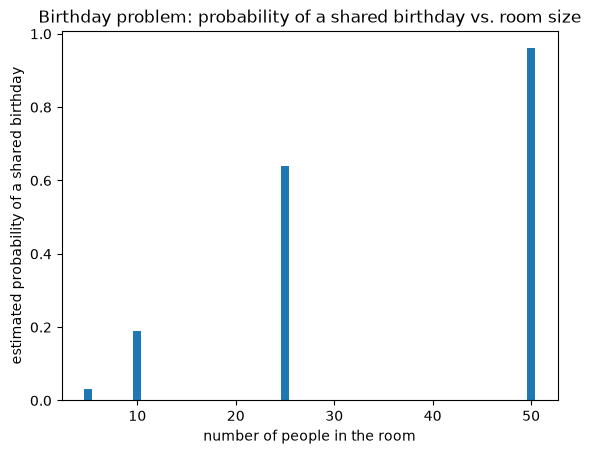

In [44]:
# Bonus - use function to generate bar plot
import matplotlib.pyplot as plt 

size = [5, 10, 25, 50]
estimates = []
num_trials = 100

for rm_size in size:
    est = estimate_probability(rm_size, num_trials)
    estimates.append(est)

print("Room sizes:", size)
print("Estimates:", estimates)
plt.bar(size, estimates)
plt.xlabel("number of people in the room")
plt.ylabel("estimated probability of a shared birthday")
plt.title("Birthday problem: probability of a shared birthday vs. room size")
plt.show()

<font size = "3">

**Ex. 3** Write a function that calculates
 $$f(x,y) = y+ x^2 + 2x + 1$$

In [45]:
# SOLUTION

def f(x,y):
    return y + x**2 + 2*x + 1

def f_long(x,y):
    output = y
    output += x**2
    output += 2 * x
    output += 1
    return output 


print(f(1, 2))
print(f_long(1, 2))



6
6


<font size = "3">

**Ex. 4** Write a function that calculates
 $$\mathbf{F}(x,y,z) = \begin{bmatrix} F_1(x,y,z)\\
 F_2(x,y,z) \\ F_3(x,y,z) \end{bmatrix} = \begin{bmatrix} x\mathrm{e}^y\\
 \mathrm{e}^{xy} \\ \sin(yz) \end{bmatrix}$$

You have a couple of choices here for the return value. 

- You could return a tuple of 3 floating point numbers.

- You could return a list of 3 floating point numbers.

- You could return a NumPy array of 3 floating point numbers (probably the best choice because mathematically, we are describing a vector).

If someone uses your function, are they able to define 3 separate floating point variables in one line when calling your function? Is this true for all 3 choices of the return value?

In [49]:
# SOLUTION - Part 1
import numpy as np

def F_tuple(x, y, z):
    F1 = x * np.exp(y)
    F2 = np.exp(x * y)
    F3 = np.sin(y * z)
    return F1, F2, F3 

def F_list(x, y, z):
    F1 = x * np.exp(y)
    F2 = np.exp(x * y)
    F3 = np.sin(y * z)
    return [F1, F2, F3]

def F_array(x, y, z):
    F1 = x * np.exp(y)
    F2 = np.exp(x * y)
    F3 = np.sin(y * z)
    return np.array([F1, F2, F3])

x = -1 
y = 0.5
z = 1/3
OUT_1 = F_tuple(x,y,z)
print(type(OUT_1), ":", OUT_1)
OUT_2 = F_list(x,y,z)
print(type(OUT_2), ":", OUT_2)
OUT_3 = F_array(x,y,z)
print(type(OUT_3), ":", OUT_3)

<class 'tuple'> : (np.float64(-1.6487212707001282), np.float64(0.6065306597126334), np.float64(0.16589613269341502))
<class 'list'> : [np.float64(-1.6487212707001282), np.float64(0.6065306597126334), np.float64(0.16589613269341502)]
<class 'numpy.ndarray'> : [-1.64872127  0.60653066  0.16589613]


In [50]:
# SOLUTION - Part 2
u = -1 
v = 0.5
w = 1/3

F1, F2, F3 = F_tuple(u, v, w)

F1, F2, F3 = F_list(u, v, w)

F1, F2, F3 = F_array(u, v, w)

# All 3 work with no error

<font size = "3">

**Ex. 5** Write a function that calculates **two quantities**.

- First, it evaluates the vector-valued function

$$\mathbf{F}(x,y,z) = \begin{bmatrix} F_1(x,y,z)\\
 F_2(x,y,z) \\ F_3(x,y,z) \end{bmatrix} = \begin{bmatrix} x\mathrm{e}^y\\
 \mathrm{e}^{xy} \\ \sin(yz) \end{bmatrix}$$

- Second, it calculates the **divergence** of the function $\mathbf{F}$ (evaluated at the same values of $x$, $y$, and $z$):

$$\begin{align*}\nabla \cdot \mathbf{F} = \textrm{div } \mathbf{F} &= \frac{\partial F_1}{\partial x}(x,y,z) + \frac{\partial F_2}{\partial y}(x,y,z) + \frac{\partial F_3}{\partial x}(x,y,z)\\
&= \mathrm{e}^y + x\mathrm{e}^{xy} + y\cos(yz)\end{align*}$$

For the return value, it is important to keep the context in mind:

- The function returns **two** mathematical objects, the vector $\mathbf{F}$ and the number $\nabla \cdot \mathbf{F} = \textrm{div } \mathbf{F}$.

- We *could* choose to return 4 numbers, where 3 of them correspond to the components of $F_1$, $F_2$, $F_3$, and the other number corresponds to the value of $\textrm{div }\mathbf{F}$. But this wouldn't be a good idea, because this obscures the fact that $F_1$, $F_2$, and $F_3$ constitute a single mathematical object.

- So instead, return two values, one for the vector $\mathbf{F}$ and another for its divergence.

If someone uses your function, are they able to define 4 separate floating point variables in one line when calling your function? 

What happens if they assign the outputs to a single variable?

In [55]:
# SOLUTION
import numpy as np

def F_and_divF(x, y, z):
    F1 = x * np.exp(y)
    F2 = np.exp(x * y)
    F3 = np.sin(y * z)

    div_F = np.exp(y) + x * np.exp(x * y) + y * np.cos(y * z)

    return np.array([F1, F2, F3]), div_F


x = 1
y = -1
z = 1/4

# Assign to one variable:
OUT = F_and_divF(x, y, z)
print("One output:")
print("Type:", type(OUT), " Length:", len(OUT))
print()

# Assign to two variables
F_val, div_val = F_and_divF(x, y, z)
print("Two outputs:")
print("Type of first output:", type(F_val), " Length of first output:", len(F_val))
print("Type of 2nd output:", type(div_val))
print()

One output:
Type: <class 'tuple'>  Length: 2

Two outputs:
Type of first output: <class 'numpy.ndarray'>  Length of first output: 3
Type of 2nd output: <class 'numpy.float64'>



In [56]:
# Try to assign to 4 variables (this fails)
out1, out2, out3, out4 = F_and_divF(x, y, z)

ValueError: not enough values to unpack (expected 4, got 2)

<font size = "3">


**Ex. 6** Write **three** separate functions, corresponding to:

- $F_1(x,y,z) = x$
- $F_2(x,y,z) = y^2 z$
- $F_3(x,y,z) = xyz^3$

Then write an additional function corresponding to:

$$ \mathbf{F}(x,y,z) = \begin{bmatrix}F_1(x,y,z) \\ F_2(x,y,z) \\ F_3(x,y,z) \end{bmatrix} $$

Do **not** re-type any mathematical commands when creating the 4th function. This function should use the 3 component functions you wrote already.

In [ ]:
# SOLUTION (version 1)

def F1(x, y, z):
    return x

def F2(x, y, z):
    return z * y**2 

def F3(x, y, z):
    return x * y * z**3

def F(x, y, z):
    component_1 = F1(x, y, z)
    component_2 = F2(x, y, z)
    component_3 = F3(x, y, z)
    return np.array([component_1, component_2, component_3])

F(1, 2, -0.125)


array([ 1.        , -0.5       , -0.00390625])

In [59]:
# SOLUTION (version 2)

def F1(x):
    return x

def F2(y, z):
    return z * y**2 

def F3(x, y, z):
    return x * y * z**3


def F(x, y, z):
    component_1 = F1(x)
    component_2 = F2(y, z)
    component_3 = F3(x, y, z)
    return np.array([component_1, component_2, component_3])

F(1, 2, -0.125)


array([ 1.        , -0.5       , -0.00390625])

In [60]:
# SOLUTION (version 2)

def F1(u):
    return u

def F2(u, t):
    return t * u**2 

def F3(var_1, var_2, var_3):
    return var_1 * var_2 * var_3**3


def F(x, y, z):
    component_1 = F1(x)
    component_2 = F2(y, z)
    component_3 = F3(x, y, z)
    return np.array([component_1, component_2, component_3])

F(1, 2, -0.125)

array([ 1.        , -0.5       , -0.00390625])

<font size = "3">


**Ex. 7** Write a function that doesn't return any values (just like the `print` function).

The function takes in 3 arguments, with the following keywords:

- `vec_x`: A sequence of values (like a list, tuple, NumPy array, or column from a Pandas DataFrame).

- `xlabel`: A string

- `title`: A string

The function creates a histogram of the values in `vec_x`, labels the x-axis using the `xlabel` argument, always labels the y-axis with the string `"Frequency"`, and adds a title using the `title` argument. It then displays the histogram to the screen.

The function should have **no return values**. You can do this by having the last line of the function read `return None`. Or simply don't include a return statement at all.

In [61]:
# complete the function
import matplotlib.pyplot as plt
def create_histogram(vec_x, xlabel, title):
    plt.hist(vec_x)
    plt.xlabel(xlabel)
    plt.ylabel("Frequency")
    plt.title(title)
    plt.show()


<font size = "3">


**Check:** If your code works, the next cell should display an appropriately labeled histogram. 

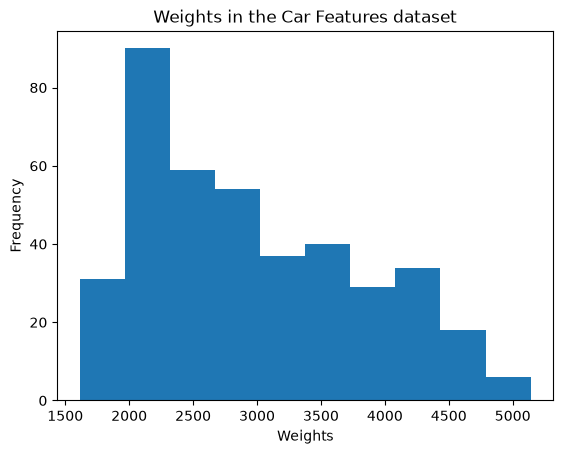

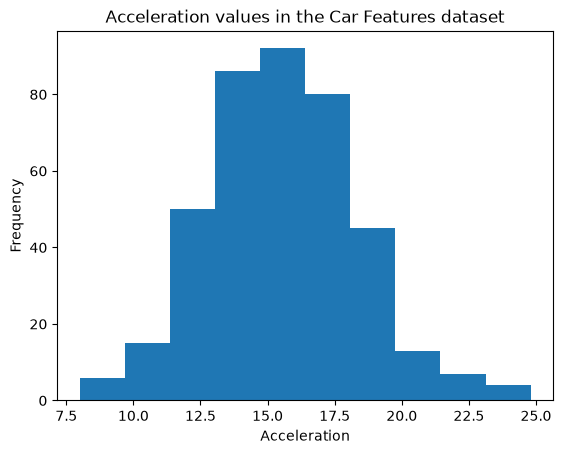

In [62]:
import pandas as pd

df = pd.read_csv("data/features.csv")

var1 = df["weight"]
label1 = "Weights" 
title1 = "Weights in the Car Features dataset"

var2 = df["acceleration"]
label2 = "Acceleration"
title2 = "Acceleration values in the Car Features dataset"

create_histogram(var1, label1, title1)
create_histogram(var2, label2, title2)

<font size = "3">


**Ex. 8** Write a function with one input argument with the keyword `numeric_grade`.

The function should return one string, depending on the value of `numeric_grade`:

- If `numeric_grade` is **greater than or equal to** 55, the return value should be the string `"status = pass"`

- Otherwise, the output value should be the string `"status = fail"`

In [64]:
# SOLUTION

def check_grade(numeric_grade):
    if numeric_grade >= 55:
        output = "status = pass"
    else:
        output = "status = fail"
    return output


def check_grade_v2(numeric_grade):
    if numeric_grade >= 55:
        return "status = pass" 
    else:
        return "status = fail"

def check_grade_v3(numeric_grade):
    if numeric_grade >= 55:
        return "status = pass" 
    return "status = fail"

print(check_grade(60))
print(check_grade_v2(60))
print(check_grade_v3(60))
print()
print(check_grade(50))
print(check_grade_v2(50))
print(check_grade_v3(50))

status = pass
status = pass
status = pass

status = fail
status = fail
status = fail


<font size = "3">


**Ex. 9** Write a function with 3 arguments, 
 `first_name`, `last_name`, `car_model`

The function should return a single string reading:

"Dear customer {first_name} {last_name},
your {car_model} is ready for pickup".

(With appropriate substitutions for the words in curly brackets)

In [65]:
# SOLUTION

def create_message(first_name, last_name, car_model):
    return f"Dear customer {first_name} {last_name}, your {car_model} is ready for pickup"

print(create_message("Peter", "Sentz", "Prius"))

Dear customer Peter Sentz, your Prius is ready for pickup


<font size = "3">


**Ex. 10** Write a function named "check_voter_eligibility" which takes in a single integer `age` as an argument.

This function should check whether age $\ge$ 18, and return the corresponding Boolean value (`True` or `False`)

In [67]:
# SOLUTION

def check_voter_eligibility(age):
    if age >= 18:
        return True 
    else:
        return False

def check_version_2(age):
    if age >= 18:
        return True 
    return False

def check_best_version(age):
    return age >= 18

age = 17
print(check_voter_eligibility(age))
print(check_version_2(age))
print(check_best_version(age))

False
False
False


<font size = "3">

In the code cell below is a list containing the ages of 5 people.

Write a for loop which checks each age for voter eligibility using the function you just wrote.

At the end of the loop, you should have a list of length 5 where each element is either ``True`` or ``False``

In [68]:
list_ages = [18,29,15,32,6]

is_eligible = []

for age in list_ages:
    is_eligible.append(check_voter_eligibility(age))

print(is_eligible)



[True, True, False, True, False]


<font size = "3">


**Ex. 11** The cell below shows the solution for Question (E) in Quiz #2. In the blank cell following it, convert the code into a **function** where the input variable is the number of "successes" needed to end the experiment, and returns the number of trials it took.

- The code cell below corresponds to the case where the input variable equals 3.

In [ ]:
import numpy as np

num_success = 0
num_trials = 0
this_prevents_infinite_loop = 0

while num_success < 3:
    outcome = np.random.choice(["Success", "Failure"], p = [0.25, 0.75])
    num_trials = num_trials + 1

    if outcome == "Success":
        num_success = num_success + 1
    

    this_prevents_infinite_loop = this_prevents_infinite_loop + 1
    if this_prevents_infinite_loop == 100000:
        print("The code shouldn't be taking this long. Try again...")
        break



print("Number of trials:", num_trials)

In [ ]:
# SOLUTION

def run_experiment(successes):
    num_success = 0
    num_trials = 0
    this_prevents_infinite_loop = 0

    while num_success < successes:
        outcome = np.random.choice(["Success", "Failure"], p = [0.25, 0.75])
        num_trials = num_trials + 1

        if outcome == "Success":
            num_success = num_success + 1
        

        this_prevents_infinite_loop = this_prevents_infinite_loop + 1
        if this_prevents_infinite_loop == 100000:
            print("The code shouldn't be taking this long. Try again...")
            return None     # optional, could also just keep the break

    return num_trials


print(run_experiment(3))
print(run_experiment(3))
print(run_experiment(12))
print(run_experiment(12))

20
13
46
30


<font size = "3">


**Ex. 12** The cell below is **almost** the solution for Question (E) in Quiz #2. The probability of success has been changed from 0.25 to 0.8.

- Rewrite the code cell so that the experiment stops after 3 **consecutive** successes.

- Then in the blank code cell, convert it to a function where the number of consecutive guesses we are waiting for is the input variable.

In [ ]:
# SOLUTION

num_success = 0
num_trials = 0
this_prevents_infinite_loop = 0


while num_success < 3:
    outcome = np.random.choice(["Success", "Failure"], p = [0.8, 0.2])
    num_trials = num_trials + 1

    if outcome == "Success":
        num_success = num_success + 1
    else:
        num_success = 0
    

    this_prevents_infinite_loop = this_prevents_infinite_loop + 1
    if this_prevents_infinite_loop == 10000000:
        print("The code shouldn't be taking this long. Try again...")
        break



print("Number of trials:", num_trials)

Number of trials: 3


In [93]:
def consecutive_experiment(consec_success):
    num_success = 0
    num_trials = 0
    this_prevents_infinite_loop = 0

    while num_success < consec_success:
        outcome = np.random.choice(["Success", "Failure"], p = [0.8, 0.2])
        num_trials = num_trials + 1

        if outcome == "Success":
            num_success = num_success + 1
        else:
            num_success = 0
        

        this_prevents_infinite_loop = this_prevents_infinite_loop + 1
        if this_prevents_infinite_loop == 10000000:
            print("The code shouldn't be taking this long. Try again...")
            return None     # optional, could also just keep the break


    return num_trials


print(consecutive_experiment(3))
print(consecutive_experiment(3))
print(consecutive_experiment(12))
print(consecutive_experiment(12))
        


3
8
107
126
